# SpaceX Falcon 9: EDA with Data Visualization
Explore how flight number, payload, launch site and orbit relate to first-stage landing success (`Class`), then prepare features for machine learning.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


### Flight Number vs Payload Mass

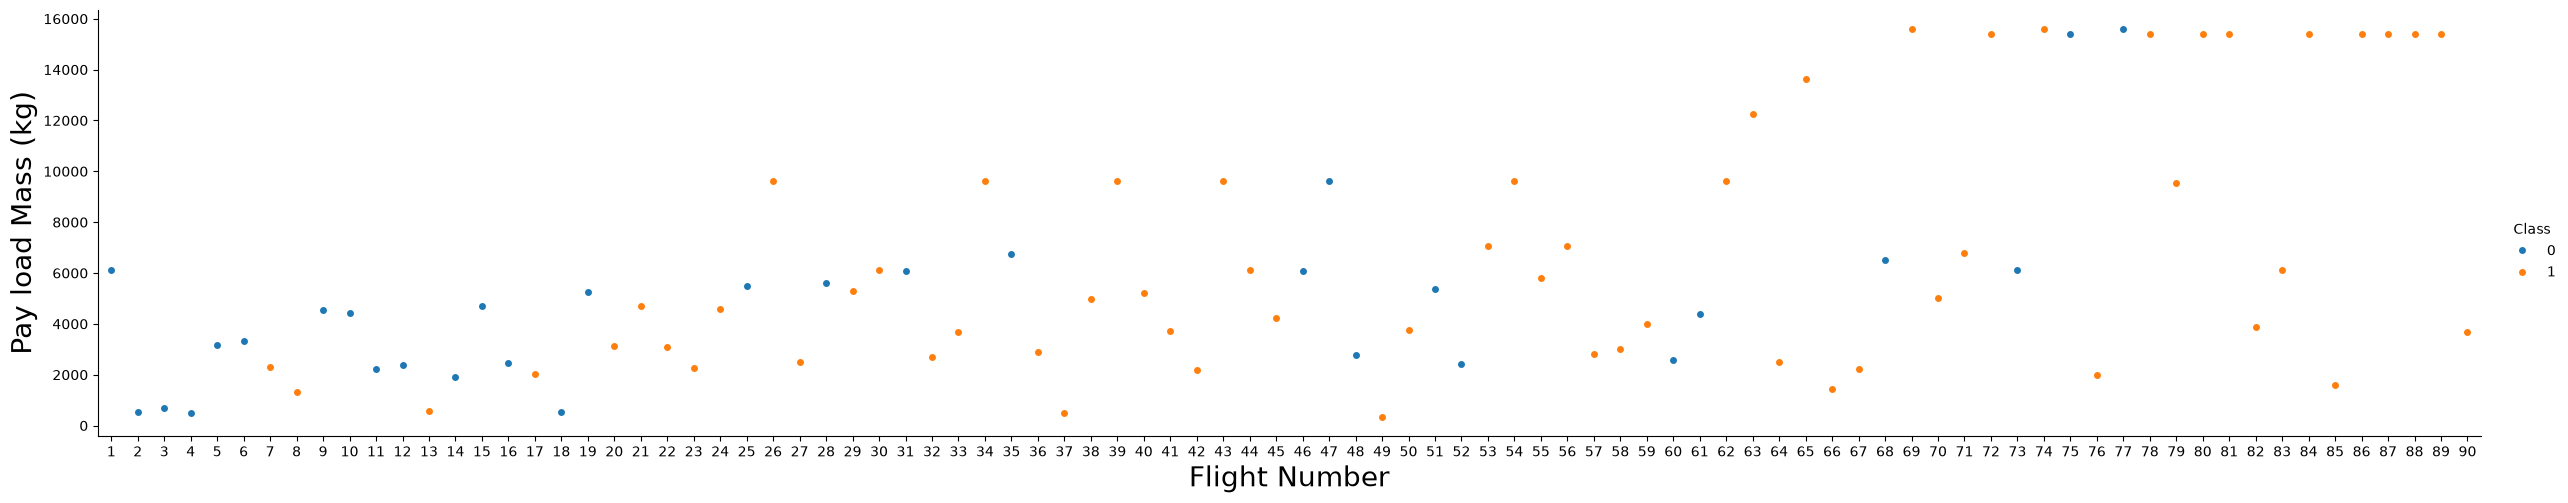

In [2]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Pay load Mass (kg)", fontsize=20); plt.show()

Success becomes more likely as flight number grows; heavier payloads do not stop the first stage from landing.

### TASK 1: Flight Number vs Launch Site

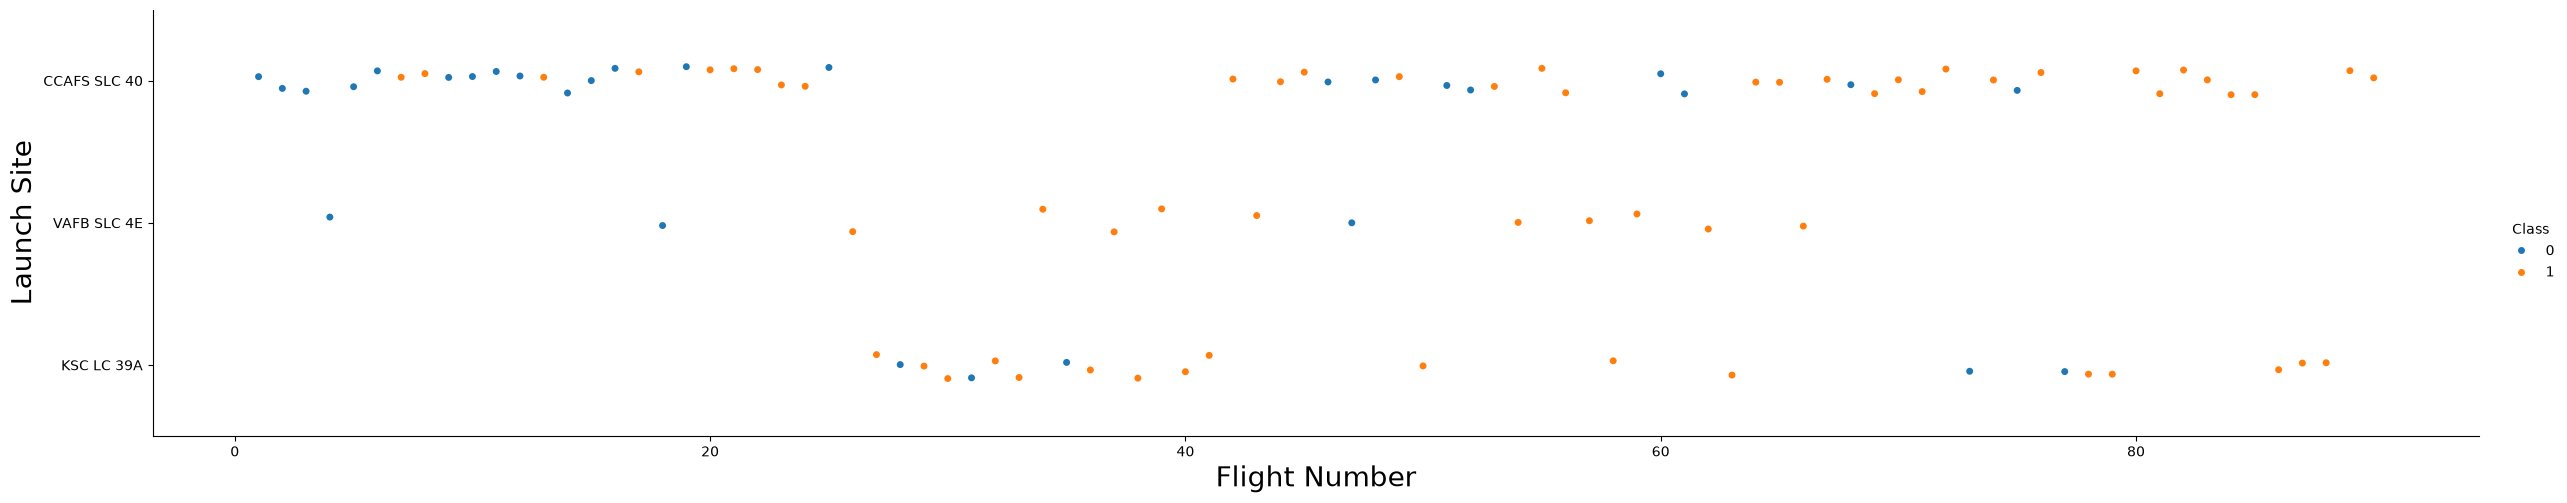

In [3]:
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Launch Site", fontsize=20); plt.show()

Most early flights (and failures) were from CCAFS SLC 40. Success improves with flight number at every site.

### TASK 2: Payload Mass vs Launch Site

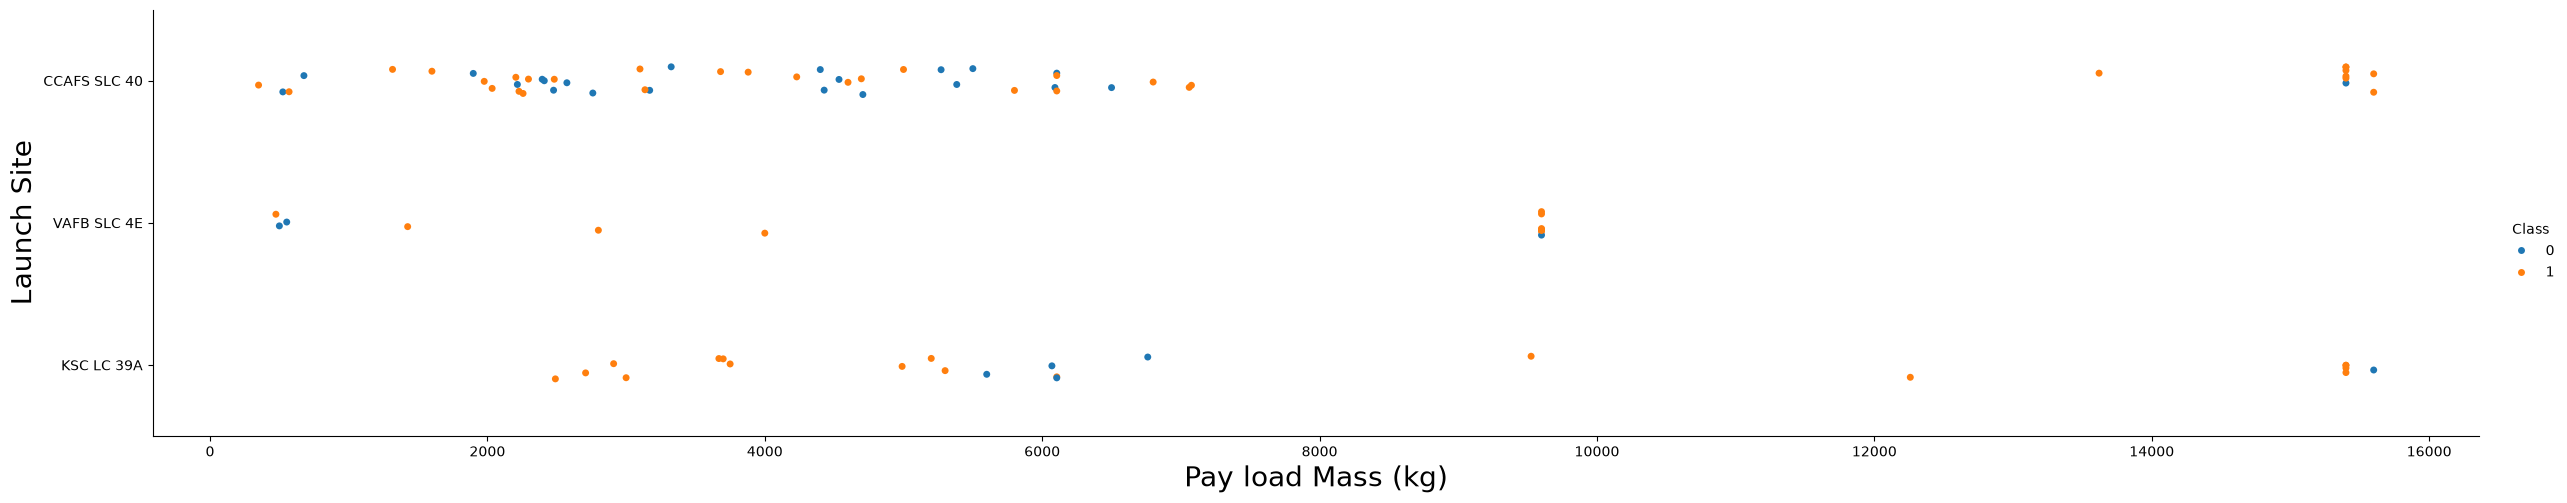

In [4]:
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Pay load Mass (kg)", fontsize=20); plt.ylabel("Launch Site", fontsize=20); plt.show()

VAFB SLC 4E has no launches with payload above 10,000 kg.

### TASK 3: Success rate of each orbit type

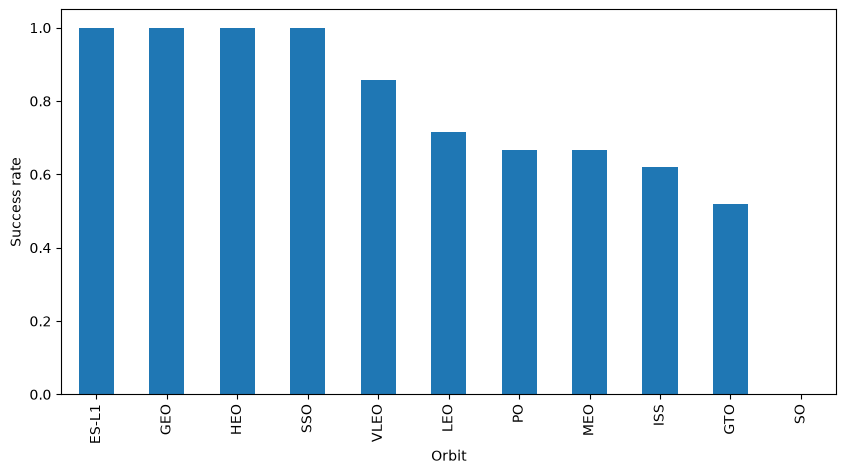

Orbit
ES-L1    1.000000
GEO      1.000000
HEO      1.000000
SSO      1.000000
VLEO     0.857143
LEO      0.714286
PO       0.666667
MEO      0.666667
ISS      0.619048
GTO      0.518519
SO       0.000000
Name: Class, dtype: float64

In [5]:
orbit_rate = df.groupby("Orbit")["Class"].mean().sort_values(ascending=False)
ax = orbit_rate.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Success rate"); plt.show()
orbit_rate

ES-L1, GEO, HEO and SSO have 100% success (ES-L1, GEO and HEO have one launch each). GTO is lowest among common orbits (~52%).

### TASK 4: Flight Number vs Orbit type

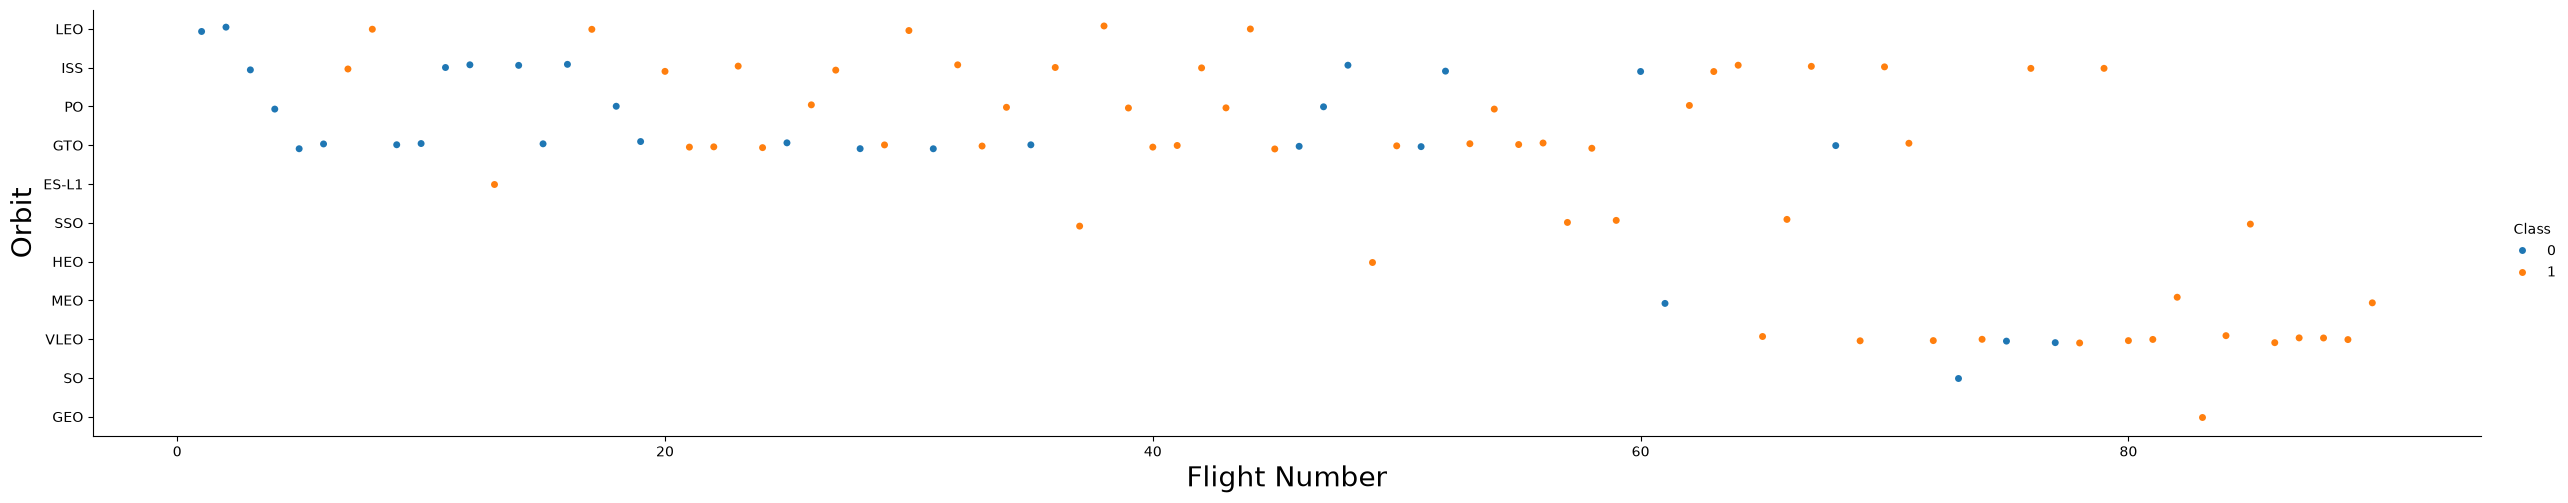

In [6]:
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Orbit", fontsize=20); plt.show()

In LEO, success appears related to the number of flights; in GTO there is no clear relationship.

### TASK 5: Payload Mass vs Orbit type

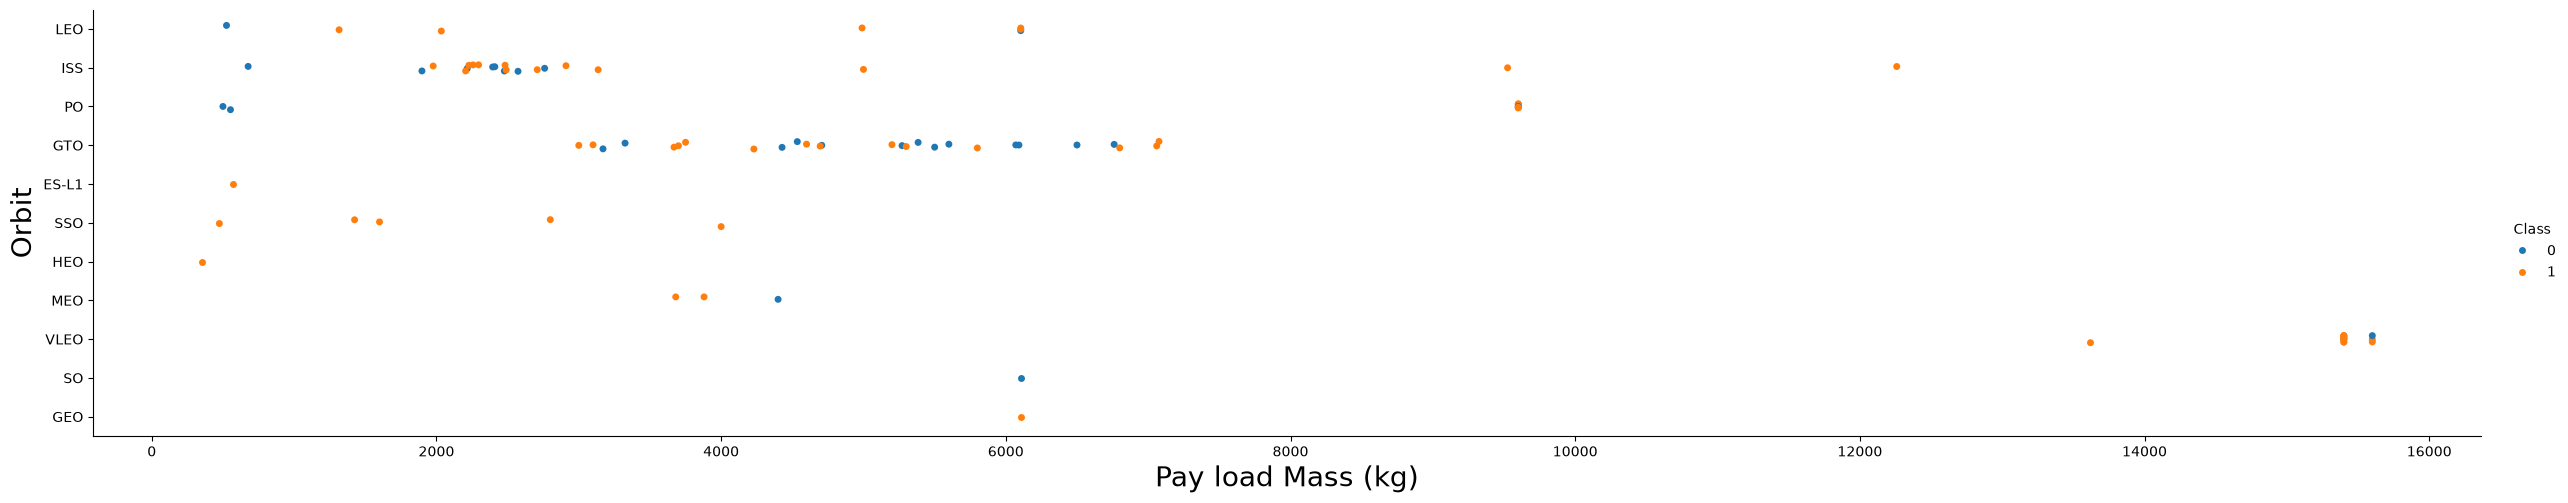

In [7]:
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Pay load Mass (kg)", fontsize=20); plt.ylabel("Orbit", fontsize=20); plt.show()

With heavy payloads, successful landings are more common for Polar, LEO and ISS. For GTO, successes and failures are mixed.

### TASK 6: Launch success yearly trend

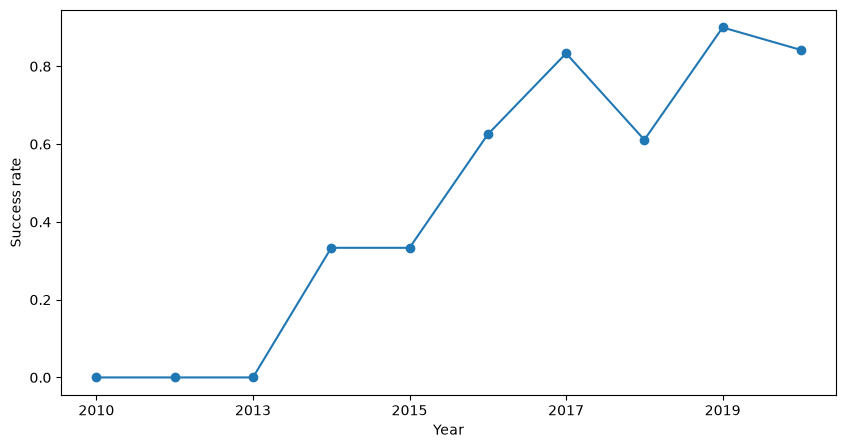

Year
2010    0.000000
2012    0.000000
2013    0.000000
2014    0.333333
2015    0.333333
2016    0.625000
2017    0.833333
2018    0.611111
2019    0.900000
2020    0.842105
Name: Class, dtype: float64

In [8]:
df["Year"] = df["Date"].str[:4]
yearly = df.groupby("Year")["Class"].mean()
yearly.plot(kind="line", marker="o", figsize=(10, 5)); plt.ylabel("Success rate"); plt.show()
yearly

The success rate has kept increasing since 2013, reaching 90% in 2019 and 84% in 2020.

## Features Engineering

In [9]:
features = df[["FlightNumber", "PayloadMass", "Orbit", "LaunchSite", "Flights", "GridFins", "Reused", "Legs", "LandingPad", "Block", "ReusedCount", "Serial"]]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


### TASK 7: Create dummy variables for categorical columns

In [10]:
features_one_hot = pd.get_dummies(features, columns=["Orbit", "LaunchSite", "LandingPad", "Serial", "GridFins", "Reused", "Legs"])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,Orbit_GTO,Orbit_HEO,Orbit_ISS,...,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062,GridFins_False,GridFins_True,Reused_False,Reused_True,Legs_False,Legs_True
0,1,6104.959412,1,1.0,0,False,False,False,False,False,...,False,False,False,False,True,False,True,False,True,False
1,2,525.000000,1,1.0,0,False,False,False,False,False,...,False,False,False,False,True,False,True,False,True,False
2,3,677.000000,1,1.0,0,False,False,False,False,True,...,False,False,False,False,True,False,True,False,True,False
3,4,500.000000,1,1.0,0,False,False,False,False,False,...,False,False,False,False,True,False,True,False,True,False
4,5,3170.000000,1,1.0,0,False,False,True,False,False,...,False,False,False,False,True,False,True,False,True,False


### TASK 8: Cast all numeric columns to `float64`

In [11]:
features_one_hot = features_one_hot.astype("float64")
print(features_one_hot.shape)
features_one_hot.to_csv("dataset_part_3.csv", index=False)

(90, 83)
